In [1]:
import sys
import os

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(REPO_ROOT, 'code'))

import numpy as np
import pandas as pd

from scunit import ScUnit

Data is loaded by passing a path to the ScUnit class. Optionally, a minimum number of mutations per cell can be specified to filter out low-coverage cells.

In [2]:
FILEPATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/SBS-count-by-cell/funnell2022single-SA604.csv'))
Y = ScUnit(FILEPATH, min_mutations=50)

Loaded 2139 cells.
Mutations per cell:
	min:  91
	mean: 514
	max:  1578


In [3]:
Y.df_mutations.iloc[:5, :8]

,A[C>A]A,A[C>A]C,A[C>A]G,A[C>A]T,A[C>G]A,A[C>G]C,A[C>G]G,A[C>G]T
cell_id,,,,,,,,
SA604X6XB01972-A96177C-R55-C31,14,16,3,14,10,12,6,8
SA604X6XB01972-A96177C-R55-C35,11,13,0,6,14,12,3,17
SA604X6XB01972-A96177C-R55-C36,12,11,1,3,9,11,1,18
SA604X6XB01972-A96177C-R56-C10,13,13,4,7,8,8,1,8
SA604X6XB01972-A96177C-R56-C18,10,17,2,7,8,9,3,10


In [4]:
Y.df_contexts.iloc[:5, :8]

,ACA,ACC,ACG,ACT,ATA,ATC,ATG,ATT
cell_id,,,,,,,,
SA604X6XB01972-A96177C-R55-C31,43,37,29,34,34,36,32,45
SA604X6XB01972-A96177C-R55-C35,43,32,20,31,24,26,29,42
SA604X6XB01972-A96177C-R55-C36,39,31,26,30,13,16,32,30
SA604X6XB01972-A96177C-R56-C10,39,30,23,25,27,17,29,32
SA604X6XB01972-A96177C-R56-C18,42,33,20,26,24,15,30,46


In [5]:
Y.df_substitutions.head()

,C>A,C>G,C>T,T>A,T>C,T>G
cell_id,,,,,,
SA604X6XB01972-A96177C-R55-C31,176,196,212,96,233,178
SA604X6XB01972-A96177C-R55-C35,140,197,209,102,175,153
SA604X6XB01972-A96177C-R55-C36,136,183,204,68,154,137
SA604X6XB01972-A96177C-R56-C10,133,150,212,79,161,118
SA604X6XB01972-A96177C-R56-C18,158,162,211,89,198,134


In [6]:
sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a']


In [7]:
COSMIC_PATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'))
cosmic = pd.read_csv(COSMIC_PATH, sep = '\t').set_index('Type').T

In [8]:
Y.deconv(signatures=cosmic.loc[sigs].T)

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
cell_id,,,,,,,,
SA604X6XB01972-A96177C-R55-C31,0.040551,0.022855,0.496576,0.195536,0.033550,0.150492,0.056783,0.003657
SA604X6XB01972-A96177C-R55-C35,0.041547,0.042541,0.641004,0.100971,0.000000,0.128402,0.034998,0.010538
SA604X6XB01972-A96177C-R55-C36,0.060975,0.034682,0.697224,0.065370,0.000000,0.106361,0.035388,0.000000
SA604X6XB01972-A96177C-R56-C10,0.051680,0.033018,0.529638,0.228224,0.015280,0.078109,0.056584,0.007468
SA604X6XB01972-A96177C-R56-C18,0.034502,0.027038,0.526512,0.225394,0.017040,0.136857,0.022928,0.009729
...,...,...,...,...,...,...,...,...
SA604X8XB02240-A96141A-R25-C66,0.058274,0.006694,0.435327,0.305899,0.081419,0.041798,0.070588,0.000000
SA604X8XB02240-A96141A-R26-C08,0.043104,0.068937,0.249350,0.405283,0.074619,0.039490,0.068210,0.051008
SA604X8XB02240-A96141A-R26-C26,0.011386,0.023273,0.245835,0.431350,0.053336,0.119586,0.103089,0.012145


In [9]:
labels = Y.umap().hdbscan().get_labels()
Y.deconv(signatures=cosmic.loc[sigs].T, aggregate_by=labels)

Silhouette: 0.9719
DBCV: 0.9856


,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
0,0.018632,0.016564,0.661444,0.063476,0.000000,0.195802,0.029907,0.014175
1,0.051005,0.040746,0.485149,0.193713,0.037005,0.128967,0.058431,0.004984


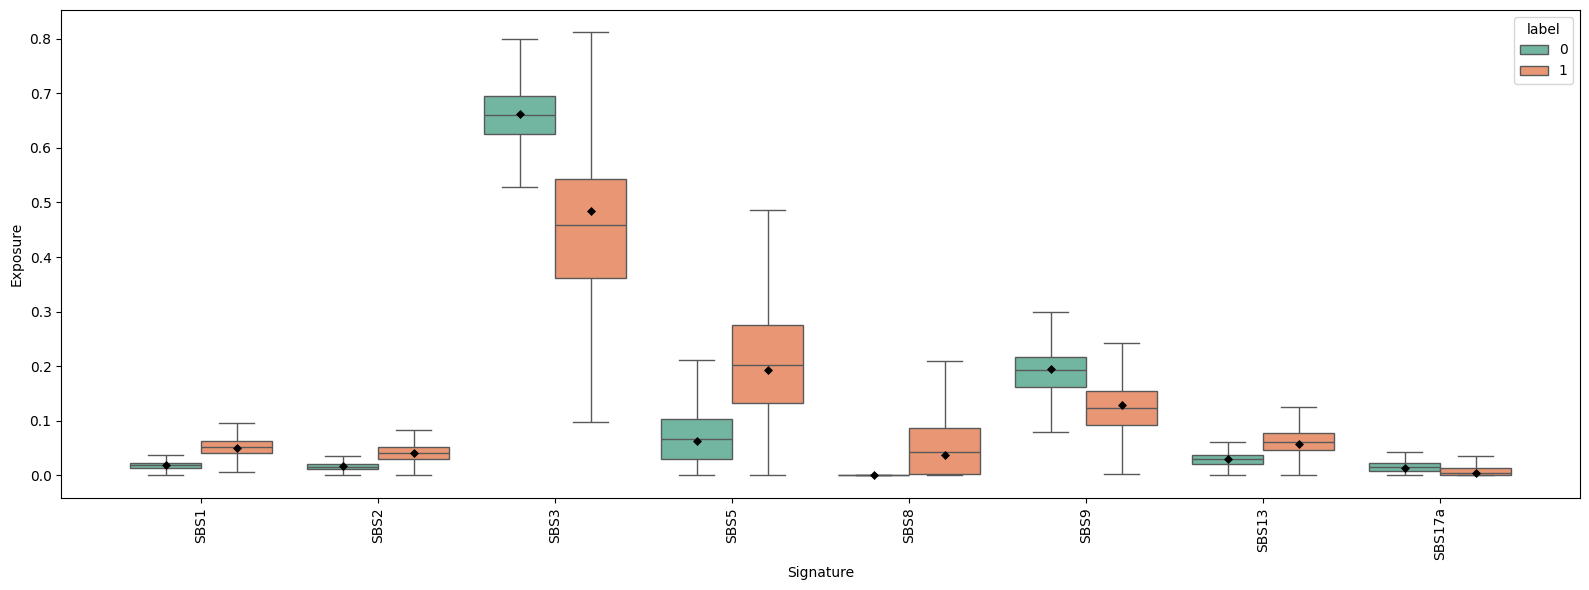

In [10]:
Y.umap().hdbscan().plot_exposures(cosmic.loc[sigs].T)

In [13]:
cosmic_contexts = cosmic.rename(columns={col: col[0] + col[2] + col[-1] for col in cosmic.columns}).groupby(level=0, axis=1).sum()
cosmic_substitutions = cosmic.rename(columns={col: col[2:5] for col in cosmic.columns}).groupby(level=0, axis=1).sum()

dmg_sig = pd.read_csv('../../data/damuta/damage_signatures.csv', index_col=0).sort_index(axis=1)
misr_sig = pd.read_csv('../../data/damuta/misrepair_signatures.csv', index_col=0).sort_index(axis=1)

In [14]:
Y.deconv(signatures=misr_sig.T)

,M1,M2,M3,M4,M5,M6
cell_id,,,,,,
SA604X6XB01972-A96177C-R55-C31,0.0,0.301956,0.182319,0.467418,0.048308,0.000000
SA604X6XB01972-A96177C-R55-C35,0.0,0.282345,0.130266,0.529451,0.016724,0.041214
SA604X6XB01972-A96177C-R55-C36,0.0,0.310029,0.162546,0.508691,0.000000,0.018734
SA604X6XB01972-A96177C-R56-C10,0.0,0.266226,0.178978,0.432788,0.041664,0.080344
SA604X6XB01972-A96177C-R56-C18,0.0,0.270386,0.214079,0.437766,0.073095,0.004674
...,...,...,...,...,...,...
SA604X8XB02240-A96141A-R25-C66,0.0,0.200275,0.212852,0.410521,0.144861,0.031490
SA604X8XB02240-A96141A-R26-C08,0.0,0.297322,0.256610,0.403857,0.042211,0.000000
SA604X8XB02240-A96141A-R26-C26,0.0,0.160224,0.142052,0.416422,0.152946,0.128356


In [17]:
Y.deconv(signatures=cosmic_substitutions.loc[sigs].T)

,SBS1,SBS2,SBS3,SBS5,SBS8,SBS9,SBS13,SBS17a
cell_id,,,,,,,,
SA604X6XB01972-A96177C-R55-C31,0.0,0.026355,0.0,0.386264,0.099349,0.331306,0.156727,0.000000
SA604X6XB01972-A96177C-R55-C35,0.0,0.084516,0.0,0.251268,0.114004,0.353546,0.196665,0.000000
SA604X6XB01972-A96177C-R55-C36,0.0,0.103402,0.0,0.250266,0.096532,0.340920,0.208880,0.000000
SA604X6XB01972-A96177C-R56-C10,0.0,0.097782,0.0,0.348066,0.121829,0.274841,0.157483,0.000000
SA604X6XB01972-A96177C-R56-C18,0.0,0.049311,0.0,0.421137,0.124850,0.262382,0.142320,0.000000
...,...,...,...,...,...,...,...,...
SA604X8XB02240-A96141A-R25-C66,0.0,0.064156,0.0,0.494847,0.185025,0.096524,0.159448,0.000000
SA604X8XB02240-A96141A-R26-C08,0.0,0.081327,0.0,0.461345,0.100465,0.183410,0.173453,0.000000
SA604X8XB02240-A96141A-R26-C26,0.0,0.081401,0.0,0.398212,0.204330,0.161122,0.142532,0.012404


In [3]:
Y.umap().hdbscan().summary()

Silhouette: 0.9719
DBCV: 0.9856


cluster_label
0     706
1    1433
Name: count, dtype: int64

In [6]:
Y.passthrough().hdbscan(min_cluster_size=10, min_samples=1).summary()

Silhouette: 0.3644
DBCV: 0.0000


cluster_label
-1     532
 0    1590
 1      17
Name: count, dtype: int64